# NLP : Résumé automatique, Question-Réponse et Génération de texte

Ce notebook implémente **trois tâches du NLP** avec des modèles Hugging Face exécutés **entièrement en local** (aucune API cloud : les modèles sont téléchargés une seule fois, puis réutilisables hors ligne) :

| # | Tâche | Modèle | Métriques |
|---|-------|--------|-----------|
| 4 | Résumé automatique (*Summarization*) | `sshleifer/distilbart-cnn-12-6` | ROUGE-1, ROUGE-2, ROUGE-L |
| 5 | Question-Réponse (*Question Answering*) | `distilbert-base-cased-distilled-squad` | Exact Match, F1 |
| 6 | Génération de texte (*Text Generation*) | `distilgpt2` | BLEU, Perplexité, Distinct-1/2 |

**Plan** : 0. Installation → 1. Imports → 2. Données → 3. Résumé → 4. QA → 5. Génération → 6. Temps de réponse et vitesse → 7. Tableau récapitulatif.

## 0. Installation des dépendances

In [1]:
%pip install -q "transformers>=4.40,<5" torch sentencepiece rouge-score sacrebleu pandas matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 1. Imports et configuration

In [2]:
import math
import time
import re
import string
import collections

import torch
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sacrebleu
from rouge_score import rouge_scorer
from transformers import (
    pipeline,
    AutoTokenizer,
    AutoModelForCausalLM,
    set_seed,
)

SEED = 42
set_seed(SEED)

DEVICE_STR = "cuda" if torch.cuda.is_available() else "cpu"
DEVICE_ID = 0 if torch.cuda.is_available() else -1   # format attendu par pipeline()
print("Device utilisé :", DEVICE_STR)

# Dossier où les graphiques sont sauvegardés (PNG)
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

LOAD_TIMES = {}   # temps de chargement de chaque modèle (en secondes)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

Device utilisé : cpu


## 2. Jeu de données d'exemple

Petit jeu de données **intégré** (pas de téléchargement de dataset) afin que le notebook soit autonome.
Chaque article sert à la fois au **résumé** (avec un résumé de référence) et au **QA** (comme contexte).
Pour un vrai benchmark, remplacez ces listes par un extrait local de CNN/DailyMail, SQuAD, etc.

In [3]:
ARTICLES = [
    "The city council approved a plan to install solar panels on all public buildings by 2030. "
    "The project is expected to cost 40 million euros and will cut the city's electricity bill by a third. "
    "Officials said the panels will also create about 200 local jobs during construction. "
    "Critics argued that the money could be better spent on public transport, but the council voted 7 to 2 in favor.",

    "Researchers at a university in Canada followed 2,000 adults for five years to study the link between sleep and memory. "
    "They found that people who slept fewer than six hours a night scored 20 percent lower on memory tests than those who slept seven to eight hours. "
    "The team also noted that regular exercise partly reduced this gap. "
    "The authors recommend that adults aim for at least seven hours of sleep and stay physically active.",

    "A small company released an open source library that lets developers run language models on ordinary laptops without a graphics card. "
    "The library compresses model weights to use less memory and reports speeds of ten tokens per second on a standard processor. "
    "Early users praised the easy installation, while some noted that accuracy drops slightly on complex reasoning tasks.",
]

REFERENCE_SUMMARIES = [
    "The city council approved a 40 million euro plan to put solar panels on all public buildings by 2030, "
    "which should cut electricity costs by a third and create about 200 jobs.",

    "A five-year study of 2,000 adults found that sleeping under six hours reduces memory test scores by 20 percent, "
    "though exercise partly offsets the effect.",

    "A new open source library compresses language models so they run on ordinary laptops at about ten tokens per second, "
    "with easy installation but slightly lower accuracy on complex reasoning.",
]

# (index de l'article-contexte, question, réponse attendue)
QA_SET = [
    (0, "How much will the project cost?", "40 million euros"),
    (0, "By what year will the panels be installed?", "2030"),
    (0, "How did the council vote?", "7 to 2"),
    (1, "How many adults were followed in the study?", "2,000"),
    (1, "How many hours of sleep do the authors recommend?", "at least seven hours"),
    (2, "How many tokens per second does the library reach?", "ten tokens per second"),
]

GEN_PROMPTS = [
    "Artificial intelligence is transforming",
    "In the future, universities will",
    "The most important skill for a data engineer is",
]
GEN_REFERENCES = [
    "the way we work, learn and communicate every day.",
    "rely more on online learning and personalized teaching.",
    "the ability to build reliable and scalable data pipelines.",
]

## 3. Résumé automatique (*Summarization*)

**Principe** : résumé **abstractif** — un modèle séquence-à-séquence (DistilBART) génère un nouveau texte plus court.

**Métrique : ROUGE** (*Recall-Oriented Understudy for Gisting Evaluation*) compare le résumé généré au résumé de référence :
- **ROUGE-1** : recouvrement des mots (unigrammes)
- **ROUGE-2** : recouvrement des paires de mots (bigrammes)
- **ROUGE-L** : plus longue sous-séquence commune

Chaque score est donné en précision / rappel / F1 ; on rapporte le **F1** (entre 0 et 1, plus c'est haut mieux c'est).

In [4]:
SUM_MODEL = "sshleifer/distilbart-cnn-12-6"
_t0 = time.perf_counter()
summarizer = pipeline("summarization", model=SUM_MODEL, device=DEVICE_ID)
LOAD_TIMES["summarization"] = time.perf_counter() - _t0

def summarize(texts, max_length=60, min_length=15):
    """Génère un résumé pour chaque texte (décodage déterministe, beam search)."""
    outputs = summarizer(
        texts,
        max_length=max_length,
        min_length=min_length,
        num_beams=4,
        do_sample=False,
        truncation=True,
    )
    return [o["summary_text"].strip() for o in outputs]

def evaluate_rouge(predictions, references):
    """Moyenne des F1 ROUGE-1 / ROUGE-2 / ROUGE-L sur tout le jeu de données."""
    scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)
    totals = collections.defaultdict(float)
    for pred, ref in zip(predictions, references):
        scores = scorer.score(ref, pred)   # (cible, prédiction)
        for name, s in scores.items():
            totals[name] += s.fmeasure
    return {name: v / len(predictions) for name, v in totals.items()}

summaries = summarize(ARTICLES)
for i, (s, r) in enumerate(zip(summaries, REFERENCE_SUMMARIES), 1):
    print(f"--- Article {i} ---")
    print("Généré   :", s)
    print("Référence:", r, "\n")

rouge_results = evaluate_rouge(summaries, REFERENCE_SUMMARIES)
print("ROUGE (F1 moyen) :", {k: round(v, 4) for k, v in rouge_results.items()})

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

Device set to use cpu


--- Article 1 ---
Généré   : The project is expected to cost 40 million euros and will cut the city's electricity bill by a third . Officials said the panels will also create about 200 local jobs during construction . Critics argued that the money could be better spent on public transport .
Référence: The city council approved a 40 million euro plan to put solar panels on all public buildings by 2030, which should cut electricity costs by a third and create about 200 jobs. 

--- Article 2 ---
Généré   : Researchers at a university in Canada followed 2,000 adults for five years to study the link between sleep and memory . They found that people who slept fewer than six hours a night scored 20 percent lower on memory tests than those who slept seven to eight hours . The authors recommend that adults aim
Référence: A five-year study of 2,000 adults found that sleeping under six hours reduces memory test scores by 20 percent, though exercise partly offsets the effect. 

--- Article 3 ---
G

### 3.1 Visualisation des résultats du résumé

- **Gauche** : scores ROUGE (F1) pour chaque article et en moyenne.
- **Droite** : longueur (en mots) de l'article, du résumé de référence et du résumé généré — permet de vérifier que le modèle compresse comme attendu.

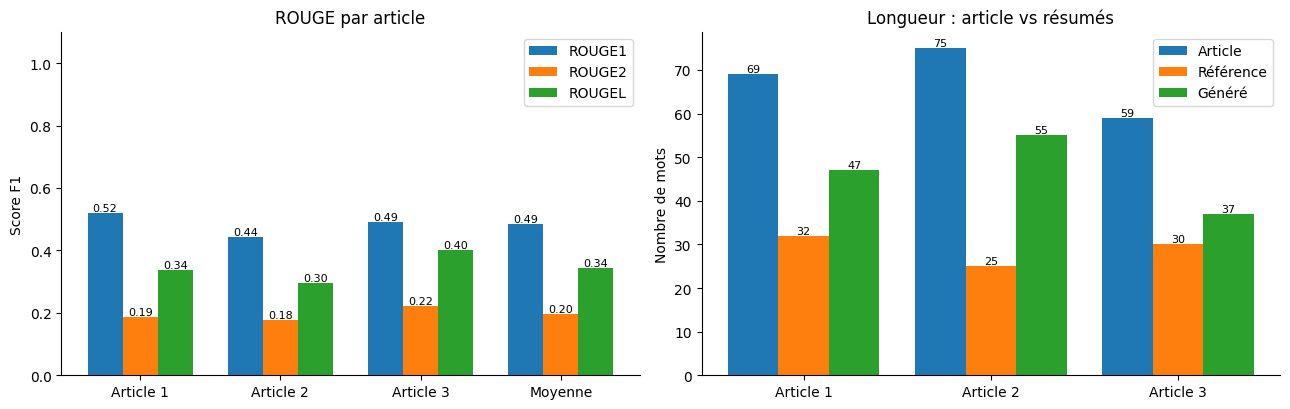

In [5]:
def rouge_per_sample(predictions, references):
    """Scores ROUGE (F1) calculés article par article."""
    scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)
    return [
        {name: s.fmeasure for name, s in scorer.score(ref, pred).items()}
        for pred, ref in zip(predictions, references)
    ]

per_sample = rouge_per_sample(summaries, REFERENCE_SUMMARIES)
labels = [f"Article {i + 1}" for i in range(len(per_sample))] + ["Moyenne"]
x = np.arange(len(labels))
width = 0.25

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))

# (1) ROUGE par article
for j, name in enumerate(["rouge1", "rouge2", "rougeL"]):
    values = [s[name] for s in per_sample] + [rouge_results[name]]
    bars = ax1.bar(x + (j - 1) * width, values, width, label=name.upper())
    ax1.bar_label(bars, fmt="%.2f", fontsize=8)
ax1.set_xticks(x)
ax1.set_xticklabels(labels)
ax1.set_ylim(0, 1.1)
ax1.set_ylabel("Score F1")
ax1.set_title("ROUGE par article")
ax1.legend()

# (2) Longueurs en mots
n_art = len(ARTICLES)
idx = np.arange(n_art)
w = 0.27
lengths = {
    "Article": [len(t.split()) for t in ARTICLES],
    "Référence": [len(t.split()) for t in REFERENCE_SUMMARIES],
    "Généré": [len(t.split()) for t in summaries],
}
for j, (name, vals) in enumerate(lengths.items()):
    bars = ax2.bar(idx + (j - 1) * w, vals, w, label=name)
    ax2.bar_label(bars, fontsize=8)
ax2.set_xticks(idx)
ax2.set_xticklabels([f"Article {i + 1}" for i in range(n_art)])
ax2.set_ylabel("Nombre de mots")
ax2.set_title("Longueur : article vs résumés")
ax2.legend()

plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "summarization_rouge.png"), dpi=150, bbox_inches="tight")
plt.show()

## 4. Question-Réponse (*Question Answering*)

**Principe** : QA **extractif** — étant donné un contexte et une question, le modèle (DistilBERT fine-tuné sur SQuAD) prédit le **segment du contexte** qui contient la réponse.

**Métriques (standard SQuAD)** :
- **Exact Match (EM)** : 1 si la réponse prédite est identique à la réponse attendue après normalisation (minuscules, sans ponctuation ni articles), sinon 0.
- **F1** : F1 calculé au niveau des **mots** partagés entre prédiction et référence (récompense les réponses partiellement correctes).

In [6]:
QA_MODEL = "distilbert-base-cased-distilled-squad"
_t0 = time.perf_counter()
qa_pipeline = pipeline("question-answering", model=QA_MODEL, device=DEVICE_ID)
LOAD_TIMES["qa"] = time.perf_counter() - _t0

def normalize_answer(s):
    """Minuscules, suppression de la ponctuation et des articles, espaces normalisés."""
    s = s.lower()
    s = "".join(ch for ch in s if ch not in set(string.punctuation))
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    return " ".join(s.split())

def exact_match(prediction, truth):
    return float(normalize_answer(prediction) == normalize_answer(truth))

def f1_score(prediction, truth):
    pred_tokens = normalize_answer(prediction).split()
    true_tokens = normalize_answer(truth).split()
    common = collections.Counter(pred_tokens) & collections.Counter(true_tokens)
    num_same = sum(common.values())
    if len(pred_tokens) == 0 or len(true_tokens) == 0:
        return float(pred_tokens == true_tokens)
    if num_same == 0:
        return 0.0
    precision = num_same / len(pred_tokens)
    recall = num_same / len(true_tokens)
    return 2 * precision * recall / (precision + recall)

def answer_questions(qa_set, contexts):
    """Retourne la liste des réponses prédites pour chaque (contexte, question)."""
    preds = []
    for ctx_idx, question, _ in qa_set:
        out = qa_pipeline(question=question, context=contexts[ctx_idx])
        preds.append(out["answer"])
    return preds

def evaluate_qa(predictions, qa_set):
    em = sum(exact_match(p, gold) for p, (_, _, gold) in zip(predictions, qa_set)) / len(qa_set)
    f1 = sum(f1_score(p, gold) for p, (_, _, gold) in zip(predictions, qa_set)) / len(qa_set)
    return {"exact_match": em, "f1": f1}

qa_preds = answer_questions(QA_SET, ARTICLES)
for (ctx_idx, q, gold), pred in zip(QA_SET, qa_preds):
    print(f"Q : {q}\n   Prédit : {pred!r} | Attendu : {gold!r} | "
          f"EM={exact_match(pred, gold):.0f} F1={f1_score(pred, gold):.2f}")

qa_results = evaluate_qa(qa_preds, QA_SET)
print("\nQA :", {k: round(v, 4) for k, v in qa_results.items()})

config.json:   0%|          | 0.00/473 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/261M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cpu


Q : How much will the project cost?
   Prédit : '40 million euros' | Attendu : '40 million euros' | EM=1 F1=1.00
Q : By what year will the panels be installed?
   Prédit : '2030' | Attendu : '2030' | EM=1 F1=1.00
Q : How did the council vote?
   Prédit : '7 to 2 in favor' | Attendu : '7 to 2' | EM=0 F1=0.75
Q : How many adults were followed in the study?
   Prédit : '2,000' | Attendu : '2,000' | EM=1 F1=1.00
Q : How many hours of sleep do the authors recommend?
   Prédit : 'at least seven' | Attendu : 'at least seven hours' | EM=0 F1=0.86
Q : How many tokens per second does the library reach?
   Prédit : 'ten' | Attendu : 'ten tokens per second' | EM=0 F1=0.40

QA : {'exact_match': 0.5, 'f1': 0.8345}


### 4.1 Visualisation des résultats du QA

Exact Match et F1 pour **chaque question** : une barre F1 > EM signale une réponse partiellement correcte (bon contenu mais segment plus long ou plus court que la référence).

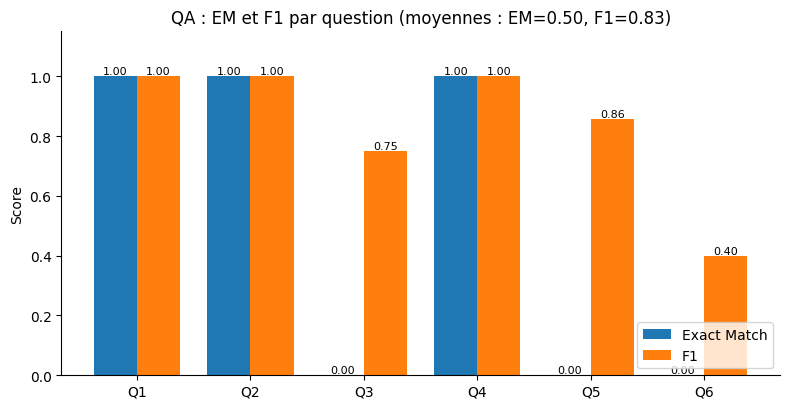

Q1 : How much will the project cost?
Q2 : By what year will the panels be installed?
Q3 : How did the council vote?
Q4 : How many adults were followed in the study?
Q5 : How many hours of sleep do the authors recommend?
Q6 : How many tokens per second does the library reach?


In [7]:
em_scores = [exact_match(p, gold) for p, (_, _, gold) in zip(qa_preds, QA_SET)]
f1_scores = [f1_score(p, gold) for p, (_, _, gold) in zip(qa_preds, QA_SET)]
labels = [f"Q{i + 1}" for i in range(len(QA_SET))]
x = np.arange(len(labels))
width = 0.38

fig, ax = plt.subplots(figsize=(8, 4.2))
b1 = ax.bar(x - width / 2, em_scores, width, label="Exact Match")
b2 = ax.bar(x + width / 2, f1_scores, width, label="F1")
ax.bar_label(b1, fmt="%.2f", fontsize=8)
ax.bar_label(b2, fmt="%.2f", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1.15)
ax.set_ylabel("Score")
ax.set_title(f"QA : EM et F1 par question (moyennes : EM={qa_results['exact_match']:.2f}, F1={qa_results['f1']:.2f})")
ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "qa_scores.png"), dpi=150, bbox_inches="tight")
plt.show()

for i, (_, question, _) in enumerate(QA_SET, 1):
    print(f"Q{i} : {question}")

## 5. Génération de texte (*Text Generation*)

**Principe** : un modèle de langage causal (DistilGPT-2) continue un *prompt* mot après mot. On compare deux stratégies de décodage :
- **greedy** : prend toujours le token le plus probable (déterministe, souvent répétitif) ;
- **sampling** : échantillonnage *top-p* + température (plus varié, moins prévisible).

**Métriques** :
- **BLEU** (sacreBLEU, 0–100) : recouvrement de n-grammes avec une continuation de référence. Peu fiable pour la génération ouverte (beaucoup de continuations valides), à interpréter avec prudence.
- **Perplexité** du texte généré selon le modèle : plus elle est basse, plus le texte est « probable » pour le modèle (fluidité).
- **Distinct-1 / Distinct-2** : proportion de unigrammes / bigrammes **uniques** dans le texte généré (mesure de la **diversité**, évite les répétitions).

In [8]:
GEN_MODEL = "distilgpt2"
_t0 = time.perf_counter()
gen_tokenizer = AutoTokenizer.from_pretrained(GEN_MODEL)
gen_model = AutoModelForCausalLM.from_pretrained(GEN_MODEL).to(DEVICE_STR)
gen_model.eval()
LOAD_TIMES["generation"] = time.perf_counter() - _t0

STRATEGIES = {
    "greedy":   dict(do_sample=False),
    "sampling": dict(do_sample=True, top_p=0.9, temperature=0.8),
}

def generate_continuation(prompt, max_new_tokens=30, **gen_kwargs):
    """Génère uniquement la continuation (sans répéter le prompt)."""
    inputs = gen_tokenizer(prompt, return_tensors="pt").to(DEVICE_STR)
    with torch.no_grad():
        output_ids = gen_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            pad_token_id=gen_tokenizer.eos_token_id,
            **gen_kwargs,
        )
    new_tokens = output_ids[0][inputs["input_ids"].shape[1]:]
    return gen_tokenizer.decode(new_tokens, skip_special_tokens=True)

def perplexity(text):
    """Perplexité d'un texte selon le modèle de génération : exp(loss moyenne)."""
    enc = gen_tokenizer(text, return_tensors="pt").to(DEVICE_STR)
    with torch.no_grad():
        loss = gen_model(**enc, labels=enc["input_ids"]).loss
    return math.exp(loss.item())

def distinct_n(text, n):
    """Ratio n-grammes uniques / n-grammes totaux (diversité lexicale)."""
    tokens = text.lower().split()
    ngrams = [tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]
    return len(set(ngrams)) / len(ngrams) if ngrams else 0.0

def evaluate_generation(prompts, references, strategy_kwargs):
    """Génère pour chaque prompt puis calcule BLEU, perplexité et Distinct-n (moyennes)."""
    set_seed(SEED)
    continuations = [generate_continuation(p, **strategy_kwargs) for p in prompts]
    bleu = sacrebleu.corpus_bleu(continuations, [references]).score
    ppl = sum(perplexity(p + c) for p, c in zip(prompts, continuations)) / len(prompts)
    d1 = sum(distinct_n(c, 1) for c in continuations) / len(continuations)
    d2 = sum(distinct_n(c, 2) for c in continuations) / len(continuations)
    return continuations, {"bleu": bleu, "perplexity": ppl, "distinct_1": d1, "distinct_2": d2}

gen_results = {}
for name, kwargs in STRATEGIES.items():
    continuations, metrics = evaluate_generation(GEN_PROMPTS, GEN_REFERENCES, kwargs)
    gen_results[name] = metrics
    print(f"=== Stratégie : {name} ===")
    for p, c in zip(GEN_PROMPTS, continuations):
        print(f"  {p}{c!r}")
    print("  Métriques :", {k: round(v, 3) for k, v in metrics.items()}, "\n")

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/353M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


=== Stratégie : greedy ===
  Artificial intelligence is transforming' the way we think about our lives.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n'
  In the future, universities will' have to decide whether to accept the idea of a new university, or whether to accept the idea of a new university.\n\n\n\n\n\n'
  The most important skill for a data engineer is' to understand the data and understand the data.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n'
  Métriques : {'bleu': 4.893, 'perplexity': 53.184, 'distinct_1': 0.78, 'distinct_2': 0.841} 

=== Stratégie : sampling ===
  Artificial intelligence is transforming' the lives of a vast swathe of the world. And the tech industry has already been playing a role in that.'
  In the future, universities will' have to consider ways of doing business with the federal government.\u202a'
  The most important skill for a data engineer is' to know how to create a simple data model.\n\n\n\n\nTo use a data engineer, you need to know how to build your 

### 5.1 Visualisation : greedy vs sampling

Une sous-figure par métrique. Sens de lecture : **↑** plus haut = mieux, **↓** plus bas = mieux.
On observe en général le compromis *fluidité* (perplexité basse avec greedy) contre *diversité* (Distinct-n plus élevé avec sampling).

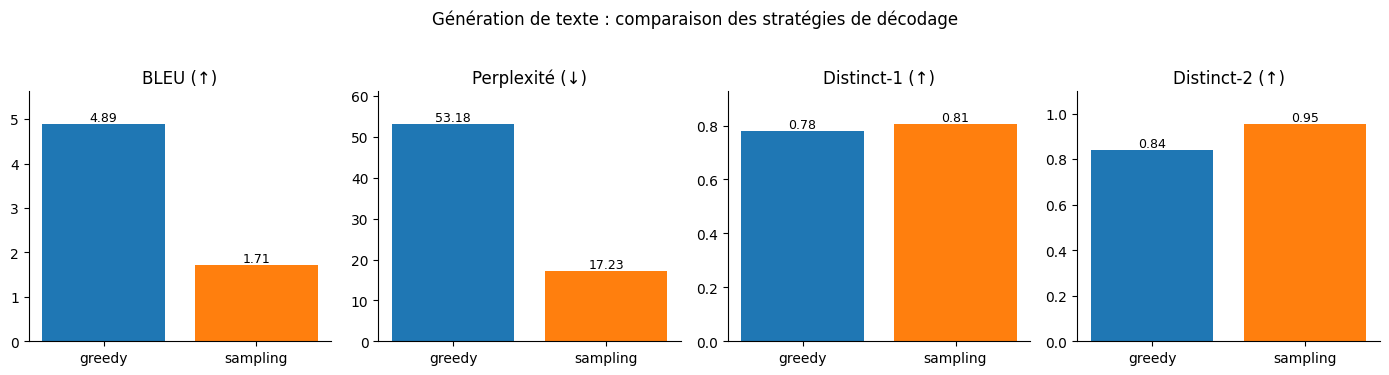

In [9]:
metric_titles = {
    "bleu": "BLEU (↑)",
    "perplexity": "Perplexité (↓)",
    "distinct_1": "Distinct-1 (↑)",
    "distinct_2": "Distinct-2 (↑)",
}
strategies = list(gen_results.keys())
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"][:len(strategies)]

fig, axes = plt.subplots(1, len(metric_titles), figsize=(14, 3.6))
for ax, (metric, title) in zip(axes, metric_titles.items()):
    values = [gen_results[s][metric] for s in strategies]
    bars = ax.bar(strategies, values, color=colors)
    ax.bar_label(bars, fmt="%.2f", fontsize=9)
    ax.set_title(title)
    ax.margins(y=0.15)
fig.suptitle("Génération de texte : comparaison des stratégies de décodage", y=1.03)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "generation_strategies.png"), dpi=150, bbox_inches="tight")
plt.show()

## 6. Temps de réponse et vitesse de chaque méthode

On mesure, pour chaque méthode, avec **une requête à la fois** (batch = 1) :

- **Latence (temps de réponse)** : durée d'un appel pour un exemple, en secondes (moyenne, écart-type, min, max).
- **Débit** : nombre d'**exemples traités par seconde** et de **tokens par seconde** (tokens *générés* pour le résumé et la génération, tokens *analysés* — question + contexte — pour le QA).
- **Temps de chargement** du modèle (mesuré lors du chargement, cellules précédentes).

**Méthodologie** : 1 appel de chauffe (*warm-up*) exclu de la mesure, puis `N_RUNS` répétitions par exemple, chronométrage avec `time.perf_counter()` et synchronisation CUDA si GPU (sinon le temps GPU asynchrone serait sous-estimé).

In [10]:
N_RUNS = 3    # répétitions chronométrées par exemple (augmentez pour une mesure plus stable)
WARMUP = 1    # appels de chauffe exclus de la mesure

HARDWARE = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print("Matériel :", HARDWARE)

def sync():
    """Attend la fin des calculs GPU (no-op sur CPU) pour un chronométrage correct."""
    if torch.cuda.is_available():
        torch.cuda.synchronize()

def benchmark(label, inputs, run_one, count_tokens, token_kind):
    """Mesure la latence et le débit d'une méthode.

    inputs       : liste d'exemples
    run_one      : fonction(exemple) -> sortie
    count_tokens : fonction(exemple, sortie) -> nombre de tokens (générés ou analysés)
    token_kind   : "générés" ou "analysés" (pour documenter la colonne Tokens/s)
    """
    times, tokens = [], 0
    for item in inputs:
        for _ in range(WARMUP):
            run_one(item)
        for _ in range(N_RUNS):
            sync()
            t0 = time.perf_counter()
            output = run_one(item)
            sync()
            times.append(time.perf_counter() - t0)
            tokens += count_tokens(item, output)
    total = sum(times)
    return {
        "Méthode": label,
        "Latence moy. (s)": float(np.mean(times)),
        "Écart-type (s)": float(np.std(times)),
        "Min (s)": float(np.min(times)),
        "Max (s)": float(np.max(times)),
        "Exemples/s": len(times) / total,
        "Tokens/s": tokens / total,
        "Type de tokens": token_kind,
    }

bench_rows = []

# --- Résumé (1 article par appel) ---
row = benchmark(
    "Résumé (DistilBART)",
    ARTICLES,
    lambda article: summarize([article])[0],
    lambda article, out: len(summarizer.tokenizer(out, add_special_tokens=False)["input_ids"]),
    "générés",
)
row["Chargement (s)"] = LOAD_TIMES["summarization"]
bench_rows.append(row)

# --- Question-Réponse (1 question par appel) ---
qa_inputs = [(ARTICLES[ctx_idx], question) for ctx_idx, question, _ in QA_SET]
row = benchmark(
    "QA (DistilBERT)",
    qa_inputs,
    lambda cq: qa_pipeline(question=cq[1], context=cq[0])["answer"],
    lambda cq, out: len(qa_pipeline.tokenizer(cq[1], cq[0])["input_ids"]),
    "analysés",
)
row["Chargement (s)"] = LOAD_TIMES["qa"]
bench_rows.append(row)

# --- Génération : une ligne par stratégie de décodage ---
for strategy_name, strategy_kwargs in STRATEGIES.items():
    row = benchmark(
        f"Génération {strategy_name} (DistilGPT-2)",
        GEN_PROMPTS,
        lambda prompt, kw=strategy_kwargs: generate_continuation(prompt, **kw),
        lambda prompt, out: len(gen_tokenizer(out, add_special_tokens=False)["input_ids"]),
        "générés",
    )
    row["Chargement (s)"] = LOAD_TIMES["generation"]
    bench_rows.append(row)

bench_df = pd.DataFrame(bench_rows).set_index("Méthode")
bench_df.round(3)

Matériel : CPU


,Latence moy. (s),Écart-type (s),Min (s),Max (s),Exemples/s,Tokens/s,Type de tokens,Chargement (s)
Méthode,,,,,,,,
Résumé (DistilBART),8.246,2.439,5.795,14.430,0.121,5.781,générés,49.372
QA (DistilBERT),0.245,0.050,0.174,0.305,4.085,362.854,analysés,6.816
Génération greedy (DistilGPT-2),1.227,0.084,1.163,1.431,0.815,17.923,générés,7.198
Génération sampling (DistilGPT-2),1.463,0.128,1.352,1.706,0.683,18.222,générés,7.198


### 6.1 Visualisation des temps de réponse et du débit

- **Gauche** : latence moyenne par appel (barres d'erreur = écart-type, échelle logarithmique car les méthodes peuvent différer d'un facteur 100).
- **Centre** : exemples traités par seconde (échelle logarithmique).
- **Droite** : tokens **générés** par seconde, uniquement pour les méthodes génératives (le QA analyse des tokens mais n'en génère pas).

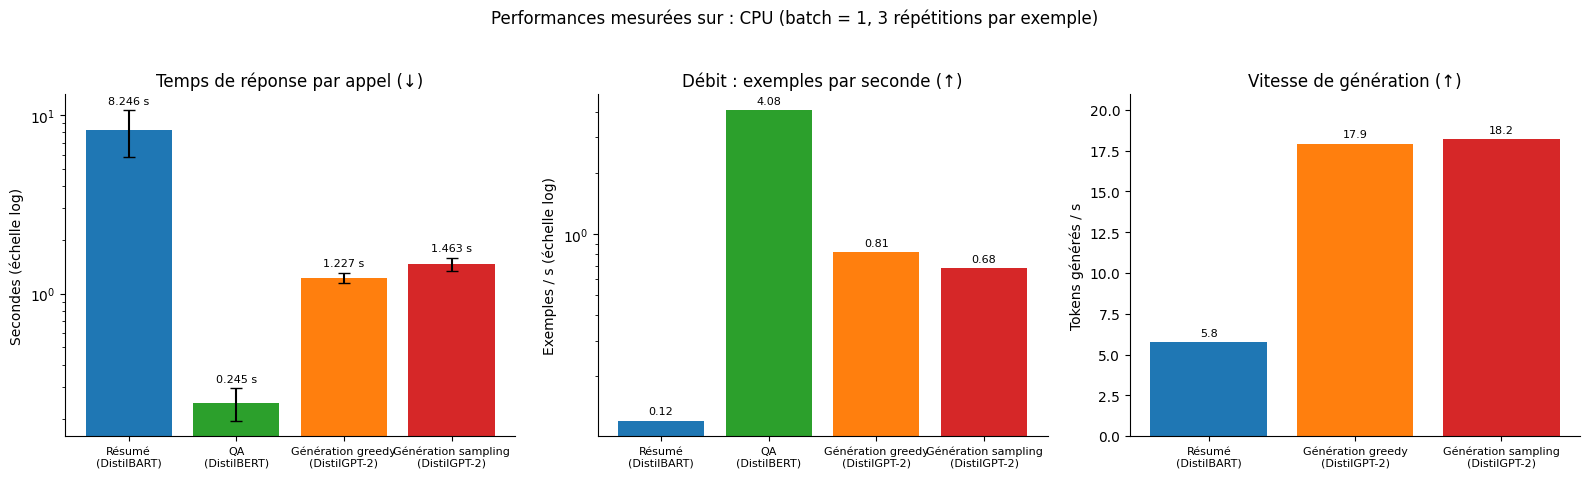

In [11]:
names = bench_df.index.tolist()
labels = [n.replace(" (", "\n(") for n in names]
colors = ["tab:blue", "tab:green", "tab:orange", "tab:red"][:len(names)]
x = np.arange(len(names))

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.6))

# (1) Latence moyenne ± écart-type
lat = bench_df["Latence moy. (s)"].values
std = bench_df["Écart-type (s)"].values
bars = ax1.bar(x, lat, yerr=std, capsize=4, color=colors)
ax1.set_yscale("log")
ax1.bar_label(bars, fmt="%.3f s", fontsize=8, padding=3)
ax1.set_xticks(x)
ax1.set_xticklabels(labels, fontsize=8)
ax1.set_ylabel("Secondes (échelle log)")
ax1.set_title("Temps de réponse par appel (↓)")

# (2) Exemples / seconde
bars = ax2.bar(x, bench_df["Exemples/s"].values, color=colors)
ax2.set_yscale("log")
ax2.bar_label(bars, fmt="%.2f", fontsize=8, padding=3)
ax2.set_xticks(x)
ax2.set_xticklabels(labels, fontsize=8)
ax2.set_ylabel("Exemples / s (échelle log)")
ax2.set_title("Débit : exemples par seconde (↑)")

# (3) Tokens générés / seconde (méthodes génératives uniquement)
gen_mask = (bench_df["Type de tokens"] == "générés").values
gx = np.arange(gen_mask.sum())
bars = ax3.bar(gx, bench_df.loc[gen_mask, "Tokens/s"].values,
               color=[c for c, m in zip(colors, gen_mask) if m])
ax3.bar_label(bars, fmt="%.1f", fontsize=8, padding=3)
ax3.set_xticks(gx)
ax3.set_xticklabels([l for l, m in zip(labels, gen_mask) if m], fontsize=8)
ax3.set_ylabel("Tokens générés / s")
ax3.set_title("Vitesse de génération (↑)")
ax3.margins(y=0.15)

fig.suptitle(f"Performances mesurées sur : {HARDWARE} (batch = 1, {N_RUNS} répétitions par exemple)", y=1.03)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "performance_timing.png"), dpi=150, bbox_inches="tight")
plt.show()

## 7. Tableau récapitulatif des résultats

In [12]:
rows = []
for k, v in rouge_results.items():
    rows.append({"Tâche": "Résumé", "Modèle": SUM_MODEL, "Métrique": k.upper(), "Score": round(v, 4)})
for k, v in qa_results.items():
    rows.append({"Tâche": "Question-Réponse", "Modèle": QA_MODEL, "Métrique": k, "Score": round(v, 4)})
for strategy, metrics in gen_results.items():
    for k, v in metrics.items():
        rows.append({"Tâche": f"Génération ({strategy})", "Modèle": GEN_MODEL, "Métrique": k, "Score": round(v, 4)})

results_df = pd.DataFrame(rows)
results_df

,Tâche,Modèle,Métrique,Score
0,Résumé,sshleifer/distilbart-cnn-12-6,ROUGE1,0.4854
1,Résumé,sshleifer/distilbart-cnn-12-6,ROUGE2,0.1954
2,Résumé,sshleifer/distilbart-cnn-12-6,ROUGEL,0.3447
3,Question-Réponse,distilbert-base-cased-distilled-squad,exact_match,0.5000
4,Question-Réponse,distilbert-base-cased-distilled-squad,f1,0.8345
5,Génération (greedy),distilgpt2,bleu,4.8928
6,Génération (greedy),distilgpt2,perplexity,53.1843
7,Génération (greedy),distilgpt2,distinct_1,0.7803
8,Génération (greedy),distilgpt2,distinct_2,0.8413
9,Génération (sampling),distilgpt2,bleu,1.7148


### 7.1 Graphique récapitulatif

Toutes les métriques bornées entre 0 et 1 sur un même axe (BLEU, sur 0–100, et la perplexité, non bornée, sont exclues pour rester comparables).

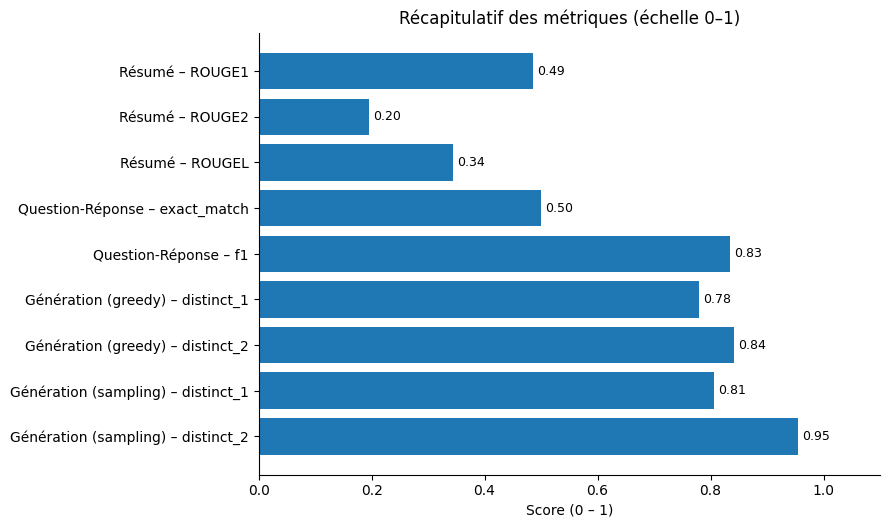

In [13]:
plot_df = results_df[~results_df["Métrique"].isin(["bleu", "perplexity"])].copy()
plot_df["Étiquette"] = plot_df["Tâche"] + " – " + plot_df["Métrique"]

fig, ax = plt.subplots(figsize=(9, 0.42 * len(plot_df) + 1.6))
bars = ax.barh(plot_df["Étiquette"], plot_df["Score"])
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_xlim(0, 1.1)
ax.set_xlabel("Score (0 – 1)")
ax.set_title("Récapitulatif des métriques (échelle 0–1)")
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "summary_metrics.png"), dpi=150, bbox_inches="tight")
plt.show()

## 8. Remarques et limites

- Le jeu de données est **volontairement minuscule** : les scores illustrent la méthode, ils ne constituent pas un benchmark. Pour des résultats significatifs, évaluez sur ≥ 500 exemples d'un dataset standard.
- **ROUGE / BLEU** mesurent un recouvrement lexical, pas le sens : deux phrases équivalentes mais reformulées obtiennent un score bas. Un complément possible est **BERTScore** (similarité sémantique, modèle local).
- **EM** est strict, **F1** plus tolérant : les deux se lisent ensemble.
- Pour la génération, la **perplexité** et **Distinct-n** se lisent ensemble : greedy → perplexité basse mais peu de diversité ; sampling → plus de diversité mais perplexité plus haute.
- Les modèles utilisés sont **petits** pour tourner sur CPU ; remplacez-les (`SUM_MODEL`, `QA_MODEL`, `GEN_MODEL`) par des versions plus grandes si vous avez un GPU.
- Les **temps de réponse** dépendent fortement du matériel (CPU vs GPU, nombre de cœurs) et de la longueur des textes : comparez les méthodes **entre elles sur la même machine**, pas avec des valeurs publiées ailleurs. Le temps de chargement d'un modèle inclut son téléchargement au premier lancement : relancez la cellule pour mesurer le chargement depuis le cache.